# งาน 1: จับคนโกง (Anti-Cheat Detection) ดูเป็นภาพ

notebook นี้อธิบายงาน 1 ตั้งแต่ข้อมูลจนถึงผล ใช้แค่ train กับผลของการรันที่มีอยู่แล้วใน `outputs/main/` ไม่เทรนโมเดลใหม่ และไม่เปิดไฟล์ test

ถ้ายังไม่มี `outputs/main/task1_oof.csv` ให้รัน `python Task1/train.py` ก่อน (ราว 1 นาทีครึ่ง)

ลำดับ
1. ข้อมูลหน้าตาเป็นยังไง
2. สิ่งที่ EDA เจอ: ช่วงค่าตายตัว และค่าว่าง
3. โมเดลทำงานยังไง
4. ผล: threshold, confusion matrix, ความน่าจะเป็น
5. ลองอะไรไปบ้าง และทำไมถึงหยุดที่ตรงนี้

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import fbeta_score, roc_auc_score, confusion_matrix

# หาโฟลเดอร์ repo (ที่มี pis/) ไม่ว่าจะเปิด notebook จากที่ไหน
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pis').is_dir())
DATA = ROOT.parent / 'cpe342-kaggle-main' / '01_binary_classification'
RUN = ROOT / 'outputs' / 'main'

LEGIT, CHEAT, GRAY = '#2a78d6', '#eb6834', '#8a8986'
plt.rcParams.update({
    'font.family': ['Leelawadee UI', 'Tahoma', 'DejaVu Sans'],
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8986', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'lines.linewidth': 2, 'figure.dpi': 110,
})

train = pd.read_csv(DATA / 'train.csv')
labelled = train[train['is_cheater'].notna()].reset_index(drop=True)
labelled['is_cheater'] = labelled['is_cheater'].astype(int)
features = [c for c in train.columns if c not in ('player_id', 'is_cheater')]
oof = pd.read_csv(RUN / 'task1_oof.csv', dtype={'player_id': str})
metrics = json.loads((RUN / 'task1_metrics.json').read_text(encoding='utf-8'))
data = labelled.merge(oof[['player_id', 'probability_1']], on='player_id', how='inner')
y, p = data['is_cheater'].to_numpy(), data['probability_1'].to_numpy()
print(f'train ทั้งหมด {len(train):,} แถว, มี label {len(labelled):,} แถว, ฟีเจอร์ {len(features)} ตัว')
print(f'ผลรันที่โหลด: {metrics["folds"]} fold, OOF Macro F2 {metrics["oof_score"]:.4f}, threshold {metrics["threshold"]:.3f}')

train ทั้งหมด 104,000 แถว, มี label 90,816 แถว, ฟีเจอร์ 31 ตัว
ผลรันที่โหลด: 10 fold, OOF Macro F2 0.7818, threshold 0.386


## 1. ข้อมูล

แต่ละแถวคือบัญชีที่ถูก flag มาแล้ว ต้องทายว่าโกงจริง (1) หรือไม่ (0) แถวที่ไม่มี label ตัดออกจากการเทรน

คะแนนคือ **Macro F2** คือค่าเฉลี่ยของ F2 ฝั่งคนโกงกับฝั่งคนปกติ F2 ให้น้ำหนัก recall มากกว่า precision 4 เท่า ปล่อยคนโกงหลุดจึงเสียคะแนนมากกว่าจับผิดคน

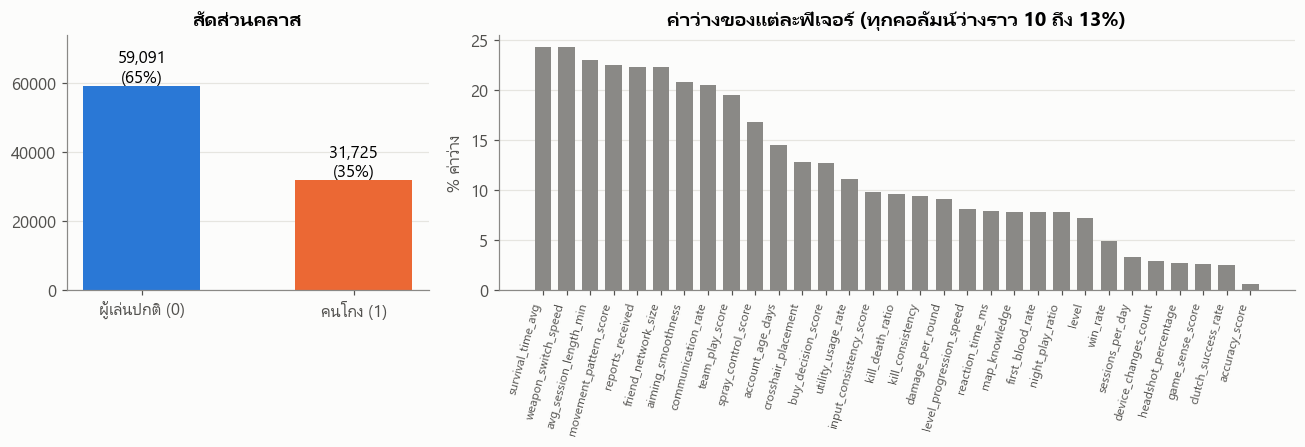

In [2]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 2.2]})

counts = labelled['is_cheater'].value_counts().sort_index()
bars = a.bar(['ผู้เล่นปกติ (0)', 'คนโกง (1)'], counts.values, color=[LEGIT, CHEAT], width=0.55)
for bar, n in zip(bars, counts.values):
    a.text(bar.get_x() + bar.get_width() / 2, n, f'{n:,}\n({n / counts.sum():.0%})', ha='center', va='bottom')
a.set_title('สัดส่วนคลาส'); a.set_ylim(0, counts.max() * 1.25); a.grid(axis='x', visible=False)

missing = labelled[features].isna().mean().sort_values(ascending=False) * 100
b.bar(range(len(missing)), missing.values, color=GRAY, width=0.7)
b.set_xticks(range(len(missing)), missing.index, rotation=75, ha='right', fontsize=8)
b.set_ylabel('% ค่าว่าง'); b.set_title('ค่าว่างของแต่ละฟีเจอร์ (ทุกคอลัมน์ว่างราว 10 ถึง 13%)')
b.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

## 2. สิ่งที่ EDA เจอ

### 2.1 ช่วงค่าตายตัว

ข้อมูลชุดนี้เป็นข้อมูลจำลอง ค่าของแต่ละกลุ่มถูกสุ่มจากช่วงที่ไม่เท่ากัน ดูกราฟข้างล่าง เส้นประสีส้มคือค่าสูงสุดที่คนโกงมีได้ เส้นประสีน้ำเงินคือค่าต่ำสุดที่คนปกติมีได้

- ค่าเกินเส้นส้ม แปลว่าไม่ใช่คนโกงแน่นอน
- ค่าต่ำกว่าเส้นน้ำเงิน แปลว่าเป็นคนโกงแน่นอน

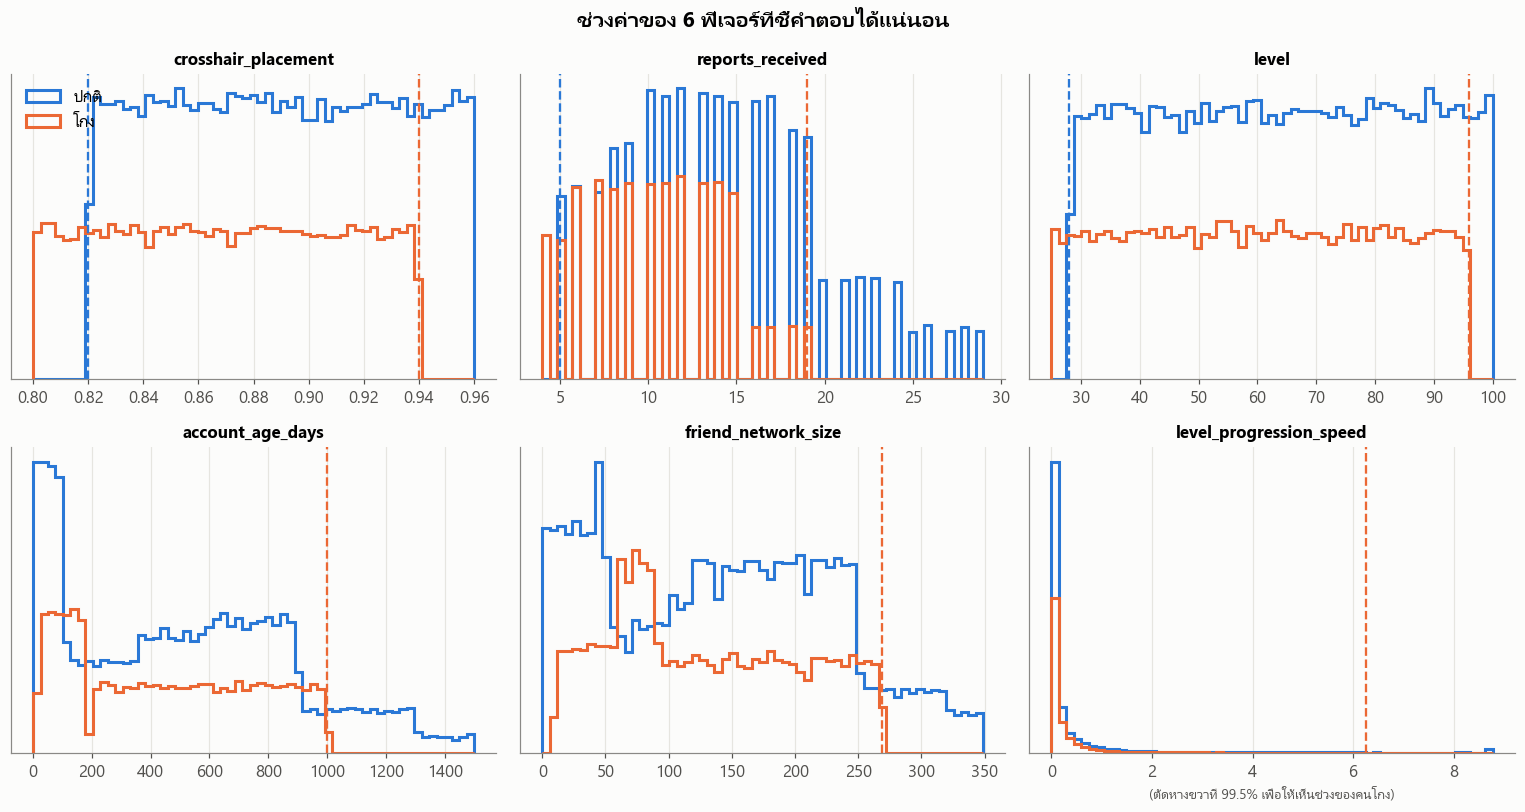

In [3]:
LEGIT_FLOOR = {'crosshair_placement': 0.82, 'reports_received': 5, 'level': 28.0}
CHEAT_CEILING = {'crosshair_placement': 0.94, 'reports_received': 19, 'account_age_days': 1000.0,
                 'friend_network_size': 269, 'level': 96.0, 'level_progression_speed': 6.26}
RULE_FEATURES = ['crosshair_placement', 'reports_received', 'level',
                 'account_age_days', 'friend_network_size', 'level_progression_speed']

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, RULE_FEATURES):
    v = labelled[col]
    hi = v.quantile(0.995) if col == 'level_progression_speed' else v.max()
    edges = np.linspace(v.min(), hi, 60)
    for label, color, name in ((0, LEGIT, 'ปกติ'), (1, CHEAT, 'โกง')):
        ax.hist(v[labelled['is_cheater'] == label].clip(upper=hi).dropna(), bins=edges, histtype='step',
                color=color, linewidth=2, label=name)
    if col in CHEAT_CEILING:
        ax.axvline(CHEAT_CEILING[col], color=CHEAT, linestyle='--', linewidth=1.5)
    if col in LEGIT_FLOOR:
        ax.axvline(LEGIT_FLOOR[col], color=LEGIT, linestyle='--', linewidth=1.5)
    ax.set_title(col, fontsize=11); ax.set_yticks([])
axes.flat[0].legend(frameon=False, loc='upper left')
axes.flat[5].set_xlabel('(ตัดหางขวาที่ 99.5% เพื่อให้เห็นช่วงของคนโกง)', fontsize=9)
fig.suptitle('ช่วงค่าของ 6 ฟีเจอร์ที่ชี้คำตอบได้แน่นอน', fontweight='bold', fontsize=14)
plt.tight_layout(); plt.show()

In [4]:
x = labelled
sure_legit = sum((x[c] > v).astype(int) for c, v in CHEAT_CEILING.items()) > 0
sure_cheat = sum((x[c] < v).astype(int) for c, v in LEGIT_FLOOR.items()) > 0
summary = pd.DataFrame({
    'กลุ่ม': ['ผู้เล่นปกติ', 'คนโกง'],
    'กฎบอกว่าปกติแน่นอน': [sure_legit[x.is_cheater == 0].mean(), sure_legit[x.is_cheater == 1].mean()],
    'กฎบอกว่าโกงแน่นอน': [sure_cheat[x.is_cheater == 0].mean(), sure_cheat[x.is_cheater == 1].mean()],
})
print('กฎผิดไหม: ปกติแน่นอนแต่จริงๆ โกง =', int((sure_legit & (x.is_cheater == 1)).sum()),
      'แถว, โกงแน่นอนแต่จริงๆ ปกติ =', int((sure_cheat & (x.is_cheater == 0)).sum()), 'แถว')
summary.style.format({c: '{:.1%}' for c in summary.columns[1:]}).hide(axis='index')

กฎผิดไหม: ปกติแน่นอนแต่จริงๆ โกง = 0 แถว, โกงแน่นอนแต่จริงๆ ปกติ = 0 แถว


กลุ่ม,กฎบอกว่าปกติแน่นอน,กฎบอกว่าโกงแน่นอน
ผู้เล่นปกติ,38.1%,0.0%
คนโกง,0.0%,19.7%


กฎพวกนี้ไม่ผิดเลยสักแถว และตอบได้แน่นอนราว 40% ของคนปกติกับ 20% ของคนโกง แถวที่เหลืออยู่ในช่วงที่สองกลุ่มซ้อนกัน ตรงนั้นโมเดลต้องเดาจากรูปแบบรวมของหลายฟีเจอร์

### 2.2 ค่าว่างคือตัวจำกัดคะแนน

ถ้าแถวไหนว่างตรงฟีเจอร์ที่ใช้ตัดสิน กฎข้างบนก็ใช้ไม่ได้ กราฟนี้คือ AUC ของโมเดลสุดท้าย (OOF) แยกตามจำนวนฟีเจอร์ที่ว่างในแถว

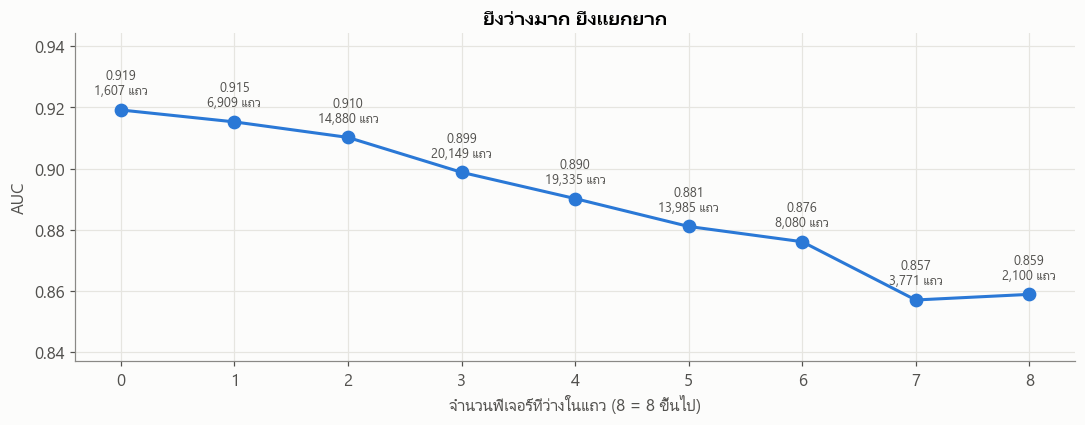

In [5]:
n_missing = data[features].isna().sum(axis=1).clip(upper=8)
rows = []
for k in range(0, 9):
    m = (n_missing == k).to_numpy()
    if m.sum() > 200 and len(np.unique(y[m])) == 2:
        rows.append((k, roc_auc_score(y[m], p[m]), m.sum()))
by_missing = pd.DataFrame(rows, columns=['ว่าง', 'AUC', 'แถว'])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_missing['ว่าง'], by_missing['AUC'], color=LEGIT, marker='o', markersize=8)
for _, r in by_missing.iterrows():
    ax.annotate(f'{r.AUC:.3f}\n{int(r["แถว"]):,} แถว', (r['ว่าง'], r.AUC), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=8.5, color='#52514e')
ax.set_xlabel('จำนวนฟีเจอร์ที่ว่างในแถว (8 = 8 ขึ้นไป)'); ax.set_ylabel('AUC')
ax.set_title('ยิ่งว่างมาก ยิ่งแยกยาก')
ax.set_ylim(by_missing['AUC'].min() - 0.02, by_missing['AUC'].max() + 0.025)
plt.tight_layout(); plt.show()

แม้แต่แถวที่ข้อมูลครบทุกช่องก็ยังได้ AUC ราว 0.92 ไม่ถึง 1 ส่วนที่เหลือเป็นการซ้อนทับของสองกลุ่มที่ข้อมูลไม่ได้บอก นี่คือเพดานของงานนี้

## 3. โมเดลทำงานยังไง

```
train.csv (แถวที่มี label 90,816 แถว)
   │
   ├─ 1. ประมาณค่าว่าง: 5 คอลัมน์ที่สำคัญ ทายค่าจากฟีเจอร์อื่นด้วย HistGradientBoosting (ไม่ใช้ label)
   │      เก็บเป็นคอลัมน์ใหม่ชื่อ ..._imp คอลัมน์เดิมยังอยู่
   ├─ 2. ฟีเจอร์กฎช่วงค่า: ระยะห่างจากขอบช่วง + จำนวนกฎที่แถวนั้นเข้าเงื่อนไข
   │      (n_sure_legit_rules, n_sure_cheat_rules)
   ├─ 3. CatBoost 10 fold: แต่ละโมเดลเทรนบน 90% ของข้อมูล ทายอีก 10% (ได้ค่า OOF ครบทุกแถว)
   │      บน test ใช้ค่าเฉลี่ยของ 10 โมเดล
   └─ 4. เลือก threshold จากค่า OOF ให้ Macro F2 สูงสุด แล้วตัดสินว่าโกงถ้าความน่าจะเป็น ≥ threshold
```

โค้ด: `pis/task1_features.py` (ขั้น 1 กับ 2) และ `pis/tabular.py` (ขั้น 3 กับ 4)

กราฟข้างล่างคือฟีเจอร์ที่ CatBoost ใช้มากที่สุด สีส้มคือฟีเจอร์ที่เราสร้างเพิ่ม สีเทาคือฟีเจอร์ดิบ

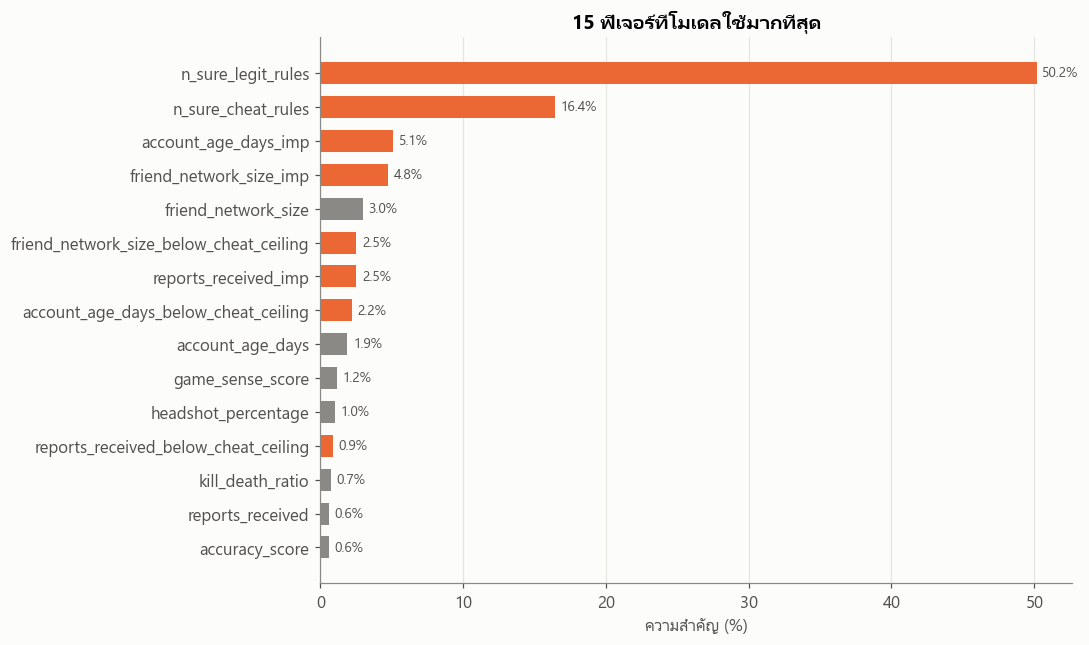

ฟีเจอร์ที่สร้างเพิ่มรวมกันได้ 86% ของความสำคัญทั้งหมด


In [6]:
imp = pd.Series(metrics['feature_importance']).sort_values(ascending=False).head(15)[::-1]
made = imp.index.str.contains('_imp|_rules|_below_|_above_')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(imp.index, imp.values, color=np.where(made, CHEAT, GRAY), height=0.65)
for i, v in enumerate(imp.values):
    ax.text(v + 0.4, i, f'{v:.1f}%', va='center', fontsize=9, color='#52514e')
ax.set_xlabel('ความสำคัญ (%)'); ax.set_title('15 ฟีเจอร์ที่โมเดลใช้มากที่สุด')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print(f'ฟีเจอร์ที่สร้างเพิ่มรวมกันได้ {pd.Series(metrics["feature_importance"])[lambda s: s.index.str.contains("_imp|_rules|_below_|_above_")].sum():.0f}% ของความสำคัญทั้งหมด')

## 4. ผล

### 4.1 เลือก threshold

โมเดลให้ความน่าจะเป็นออกมา ต้องเลือกว่าเกินเท่าไรถึงตัดสินว่าโกง ถ้าใช้ 0.5 ตามปกติจะได้ Macro F2 0.760 แต่ F2 ชอบ recall จึงควรตัดที่ต่ำกว่า กราฟนี้ไล่ threshold ทุกค่าบน OOF

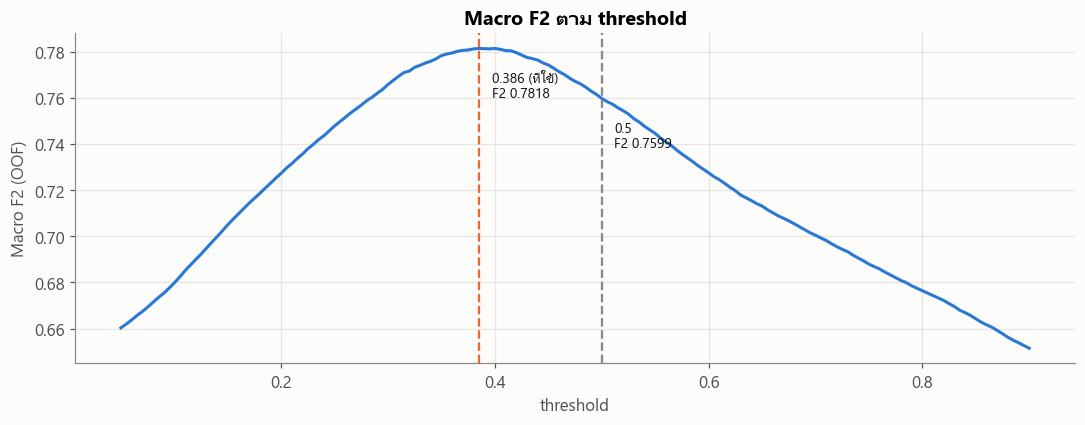

In [7]:
grid = np.linspace(0.05, 0.9, 171)
scores = [fbeta_score(y, p >= t, beta=2, average='macro') for t in grid]
best_t = metrics['threshold']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid, scores, color=LEGIT)
for t, name, color in ((0.5, '0.5', GRAY), (best_t, f'{best_t:.3f} (ที่ใช้)', CHEAT)):
    s = fbeta_score(y, p >= t, beta=2, average='macro')
    ax.axvline(t, color=color, linestyle='--', linewidth=1.5)
    ax.annotate(f'{name}\nF2 {s:.4f}', (t, s), textcoords='offset points', xytext=(8, -32), color='#0b0b0b', fontsize=9)
ax.set_xlabel('threshold'); ax.set_ylabel('Macro F2 (OOF)'); ax.set_title('Macro F2 ตาม threshold')
plt.tight_layout(); plt.show()

ข้อควรระวัง: เลือก threshold และวัดผลบน OOF ชุดเดียวกัน คะแนนนี้จึงสูงกว่าความจริงเล็กน้อย แต่ตอนส่ง Kaggle ผลที่ได้ก็ตรงกับที่ CV ทำนายไว้

### 4.2 ทายถูกผิดแค่ไหน

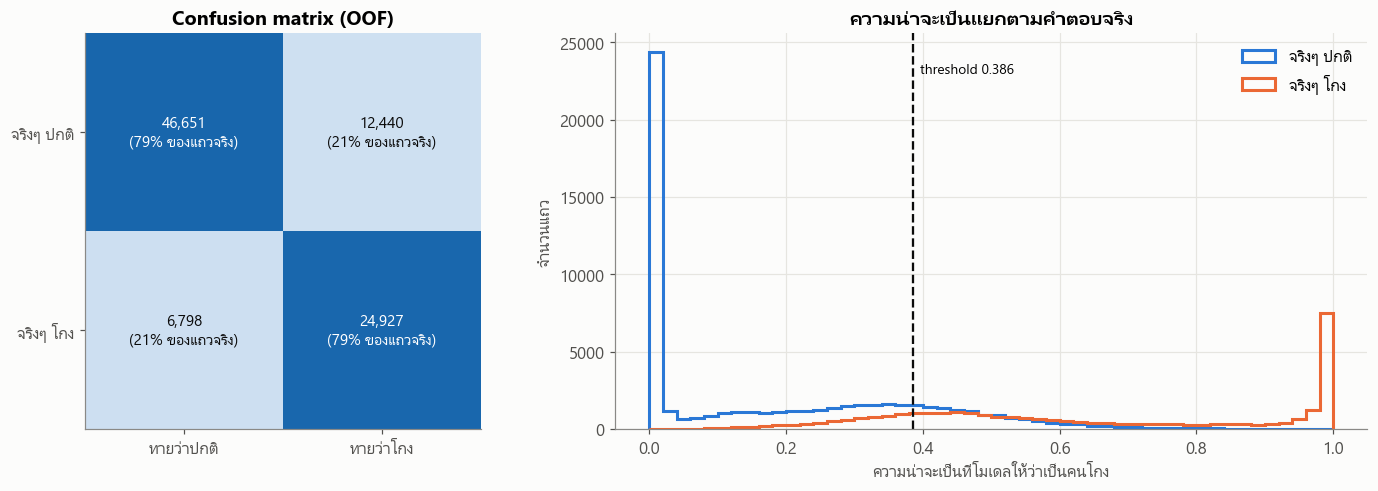

จับคนโกงได้ 78.6% (recall), ในที่ทายว่าโกงถูก 66.7% (precision)


In [8]:
pred = (p >= best_t).astype(int)
cm = confusion_matrix(y, pred)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.6]})
a.imshow(cm / cm.sum(axis=1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
names = ['ปกติ', 'โกง']
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        a.text(j, i, f'{cm[i, j]:,}\n({share:.0%} ของแถวจริง)', ha='center', va='center',
               color='white' if share > 0.5 else '#0b0b0b', fontsize=10)
a.set_xticks([0, 1], [f'ทายว่า{n}' for n in names]); a.set_yticks([0, 1], [f'จริงๆ {n}' for n in names])
a.grid(False); a.set_title('Confusion matrix (OOF)')

edges = np.linspace(0, 1, 51)
b.hist(p[y == 0], bins=edges, histtype='step', color=LEGIT, linewidth=2, label='จริงๆ ปกติ')
b.hist(p[y == 1], bins=edges, histtype='step', color=CHEAT, linewidth=2, label='จริงๆ โกง')
b.axvline(best_t, color='#0b0b0b', linestyle='--', linewidth=1.5)
b.text(best_t + 0.01, b.get_ylim()[1] * 0.9, f'threshold {best_t:.3f}', fontsize=9)
b.set_xlabel('ความน่าจะเป็นที่โมเดลให้ว่าเป็นคนโกง'); b.set_ylabel('จำนวนแถว')
b.set_title('ความน่าจะเป็นแยกตามคำตอบจริง'); b.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f'จับคนโกงได้ {cm[1, 1] / cm[1].sum():.1%} (recall), ในที่ทายว่าโกงถูก {cm[1, 1] / cm[:, 1].sum():.1%} (precision)')

ด้านขวามีสองยอดที่ปลาย คนปกติราว 24,000 คนได้ความน่าจะเป็นใกล้ 0 และคนโกงราว 7,000 คนได้ใกล้ 1 พวกนี้คือแถวที่กฎช่วงค่าตอบได้แน่นอน ตรงกลางระหว่าง 0.1 ถึง 0.8 สองเส้นซ้อนกันเกือบสนิท คะแนนที่เสียเกือบทั้งหมดมาจากช่วงนี้ threshold 0.386 อยู่ตรงที่สองเส้นตัดกันพอดี ทำให้จับคนโกงได้มาก แลกกับจับคนปกติผิด 21% ซึ่ง F2 ยอมรับได้

## 5. ลองอะไรไปบ้าง

ทุกแถวในกราฟนี้วัดด้วย 3 fold ชุดเดียวกัน (ยกเว้น 5 กับ 10 fold) ตัวเลขมาจาก `Task1/README.md`

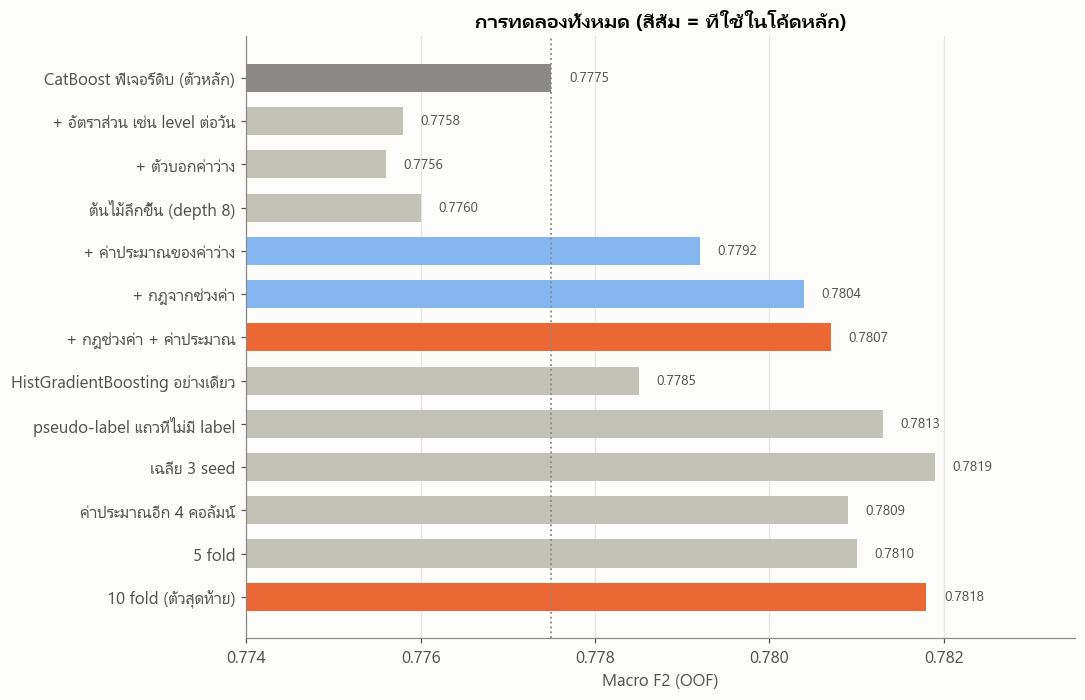

In [9]:
trials = [
    ('CatBoost ฟีเจอร์ดิบ (ตัวหลัก)', 0.7775, 'base'),
    ('+ อัตราส่วน เช่น level ต่อวัน', 0.7758, 'no'),
    ('+ ตัวบอกค่าว่าง', 0.7756, 'no'),
    ('ต้นไม้ลึกขึ้น (depth 8)', 0.7760, 'no'),
    ('+ ค่าประมาณของค่าว่าง', 0.7792, 'part'),
    ('+ กฎจากช่วงค่า', 0.7804, 'part'),
    ('+ กฎช่วงค่า + ค่าประมาณ', 0.7807, 'used'),
    ('HistGradientBoosting อย่างเดียว', 0.7785, 'no'),
    ('pseudo-label แถวที่ไม่มี label', 0.7813, 'no'),
    ('เฉลี่ย 3 seed', 0.7819, 'no'),
    ('ค่าประมาณอีก 4 คอลัมน์', 0.7809, 'no'),
    ('5 fold', 0.7810, 'no'),
    ('10 fold (ตัวสุดท้าย)', 0.7818, 'used'),
]
colors = {'base': GRAY, 'no': '#c3c2b7', 'part': '#86b6ef', 'used': CHEAT}
fig, ax = plt.subplots(figsize=(10, 6.5))
names, vals, kinds = zip(*trials[::-1])
ax.barh(names, vals, color=[colors[k] for k in kinds], height=0.65)
for i, v in enumerate(vals):
    ax.text(v + 0.0002, i, f'{v:.4f}', va='center', fontsize=9, color='#52514e')
ax.axvline(0.7775, color=GRAY, linestyle=':', linewidth=1.2)
ax.set_xlim(0.774, 0.7835); ax.set_xlabel('Macro F2 (OOF)')
ax.set_title('การทดลองทั้งหมด (สีส้ม = ที่ใช้ในโค้ดหลัก)'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

เฉลี่ย 3 seed กับ pseudo-label ได้ใกล้ๆ 10 fold แต่ต่างจากตัวที่ใช้ไม่เกิน 0.0013 ซึ่งน้อยกว่าความต่างระหว่าง fold (0.756 ถึง 0.763) และเอามารวมกันก็ไม่บวกเพิ่ม จึงไม่ใส่

### 5.1 ทำไม 10 fold ถึงผ่าน

ถ้าแค่เปลี่ยนวิธีสุ่มแบ่งข้อมูล (seed ของการแบ่ง) คะแนนจะแกว่งเอง กราฟนี้เทียบความแกว่งนั้นกับผลของการเพิ่มจำนวน fold

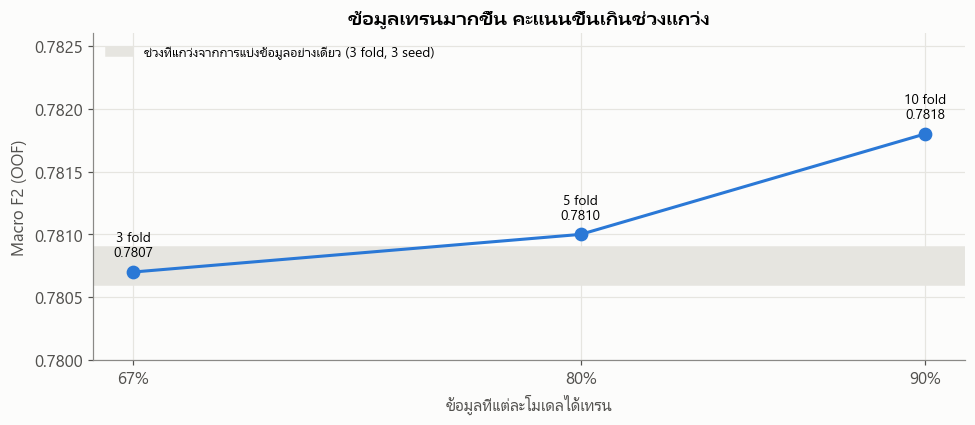

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
split_seeds = [0.7807, 0.7809, 0.7806]
ax.axhspan(min(split_seeds), max(split_seeds), color='#e6e5e0', label='ช่วงที่แกว่งจากการแบ่งข้อมูลอย่างเดียว (3 fold, 3 seed)')
ax.plot([67, 80, 90], [0.7807, 0.7810, 0.7818], color=LEGIT, marker='o', markersize=8)
for x_, v, k in ((67, 0.7807, 3), (80, 0.7810, 5), (90, 0.7818, 10)):
    ax.annotate(f'{k} fold\n{v:.4f}', (x_, v), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.set_xticks([67, 80, 90], ['67%', '80%', '90%']); ax.set_xlabel('ข้อมูลที่แต่ละโมเดลได้เทรน')
ax.set_ylabel('Macro F2 (OOF)'); ax.set_ylim(0.7800, 0.7826)
ax.set_title('ข้อมูลเทรนมากขึ้น คะแนนขึ้นเกินช่วงแกว่ง'); ax.legend(frameon=False, loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

## 6. ผลบน Kaggle และสรุป

| ไฟล์ | คะแนนรวม 5 งาน |
|---|---|
| ตัวตั้งต้นของทีม | 0.72635 |
| + งาน 1 รุ่น 3 fold | 0.72692 |
| + งาน 1 + งาน 2 | 0.72792 |

คะแนนรวมคือค่าเฉลี่ยของ 5 งาน งาน 1 ทำให้คะแนนรวมขึ้น 0.00057 เท่ากับงาน 1 บน test ดีขึ้นราว 0.0029 ใกล้กับ 0.0032 ที่ CV ทำนายไว้ ผลในเครื่องจึงเชื่อได้ รุ่น 10 fold ยังไม่ได้ส่งแยก

สรุปสั้นๆ
- ข้อมูลจำลองมีช่วงค่าตายตัว เราแปลงช่วงนั้นเป็นฟีเจอร์ให้โมเดล และเติมค่าว่างด้วยค่าประมาณ
- เทรน CatBoost 10 fold แล้วเลือก threshold 0.386 ให้เข้ากับ F2
- ได้ OOF Macro F2 0.7818 จากตัวหลัก 0.7775
- ที่เหลือคือการซ้อนทับของสองกลุ่มกับค่าว่างที่กู้คืนไม่ได้ เพิ่มอะไรก็ได้ไม่ถึง 0.001